<a href="https://colab.research.google.com/github/phantomfenix/NVME-PROJECT/blob/main/K_medias_y_jerarquico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pkgs<-c("factoextra","NbClust","cluster","fpc","dendextend")

In [ ]:
install.packages(pkgs)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘SparseM’, ‘MatrixModels’, ‘sp’, ‘minqa’, ‘nloptr’, ‘RcppEigen’, ‘lazyeval’, ‘later’, ‘carData’, ‘pbkrtest’, ‘quantreg’, ‘maptools’, ‘lme4’, ‘htmlwidgets’, ‘crosstalk’, ‘promises’, ‘estimability’, ‘numDeriv’, ‘mvtnorm’, ‘xtable’, ‘corrplot’, ‘car’, ‘DT’, ‘ellipse’, ‘emmeans’, ‘flashClust’, ‘leaps’, ‘multcompView’, ‘scatterplot3d’, ‘ggsci’, ‘cowplot’, ‘ggsignif’, ‘gridExtra’, ‘polynom’, ‘rstatix’, ‘plyr’, ‘Rcpp’, ‘modeltools’, ‘DEoptimR’, ‘abind’, ‘FactoMineR’, ‘ggpubr’, ‘reshape2’, ‘ggrepel’, ‘mclust’, ‘flexmix’, ‘prabclus’, ‘diptest’, ‘robustbase’, ‘kernlab’, ‘viridis’




**factoextra:** extract and visualize the output of multivariate data analyses

**NbClust:**  provides 30 indices for determining the number of clusters and proposes to user the best clustering scheme from the different results obtained by varying all combinations of number of clusters, distance measures, and clustering methods.

**fpc:** Various methods for clustering and cluster validation.

**cluster:** Methods for Cluster analysis.

In [ ]:
library(factoextra);library(NbClust);library(fpc);library(cluster);

Loading required package: ggplot2

Welcome! Want to learn more? See two factoextra-related books at https://goo.gl/ve3WBa



In [ ]:
data("USArrests")

In [ ]:
?USArrests

In [ ]:
head(USArrests)

,Murder,Assault,UrbanPop,Rape
,<dbl>,<int>,<int>,<dbl>
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6
Colorado,7.9,204,78,38.7


In [ ]:
View(USArrests)

,Murder,Assault,UrbanPop,Rape
,<dbl>,<int>,<int>,<dbl>
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6
Colorado,7.9,204,78,38.7
Connecticut,3.3,110,77,11.1
Delaware,5.9,238,72,15.8
Florida,15.4,335,80,31.9


In [ ]:
any(is.na(USArrests))

[1] FALSE

In [ ]:
library(tidyverse)

Warning message in system("timedatectl", intern = TRUE):
“running command 'timedatectl' had status 1”
── Attaching packages ─────────────────────────────────────── tidyverse 1.3.1 ──

✔ tibble  3.1.7      ✔ dplyr   1.0.10
✔ tidyr   1.2.1      ✔ stringr 1.4.1 
✔ readr   2.1.2      ✔ forcats 0.5.2 
✔ purrr   0.3.4      

── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()



Buscamos valores extremos

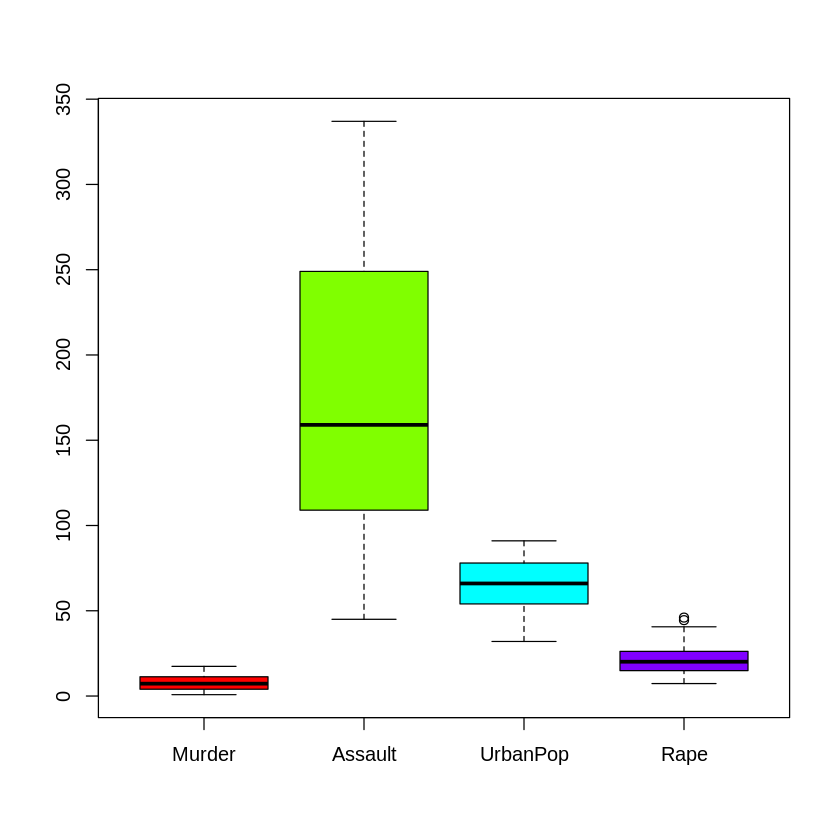

In [ ]:
boxplot(USArrests, col = rainbow(ncol(USArrests)))

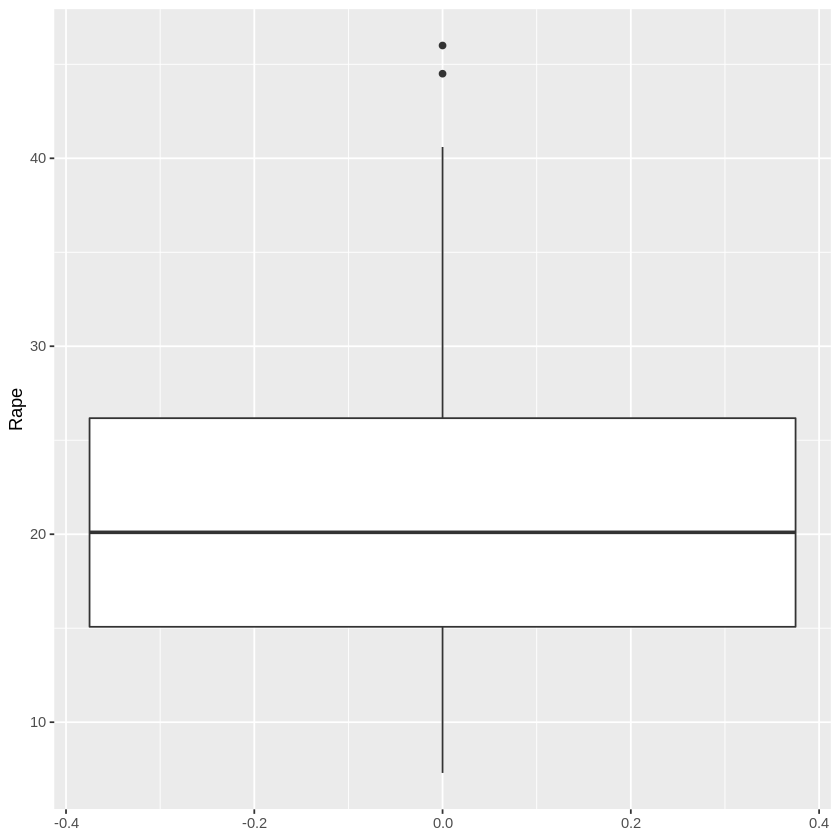

In [ ]:
ggplot(USArrests, aes(y=Rape))+geom_boxplot()

Aquí si hay

Estandarizamos los datos.

In [ ]:
df<-scale(USArrests)

In [ ]:
View(df)

,Murder,Assault,UrbanPop,Rape
Alabama,1.24256408,0.78283935,-0.52090661,-0.003416473
Alaska,0.50786248,1.10682252,-1.21176419,2.484202941
Arizona,0.07163341,1.47880321,0.99898006,1.042878388
Arkansas,0.23234938,0.23086801,-1.07359268,-0.184916602
California,0.27826823,1.26281442,1.75892340,2.067820292
Colorado,0.02571456,0.39885929,0.86080854,1.864967207
Connecticut,-1.03041900,-0.72908214,0.79172279,-1.081740768
Delaware,-0.43347395,0.80683810,0.44629400,-0.579946294
Florida,1.74767144,1.97077766,0.99898006,1.138966691
Georgia,2.20685994,0.48285493,-0.38273510,0.487701523


Alaska y Nevada son los que tienen los valores atípicos. Como están a menos de 3 desviación estándar podemos dejarlos.

Podemos usar PCA para visualizar los datos para buscar clusters.

In [ ]:
library(corrplot)

corrplot 0.92 loaded



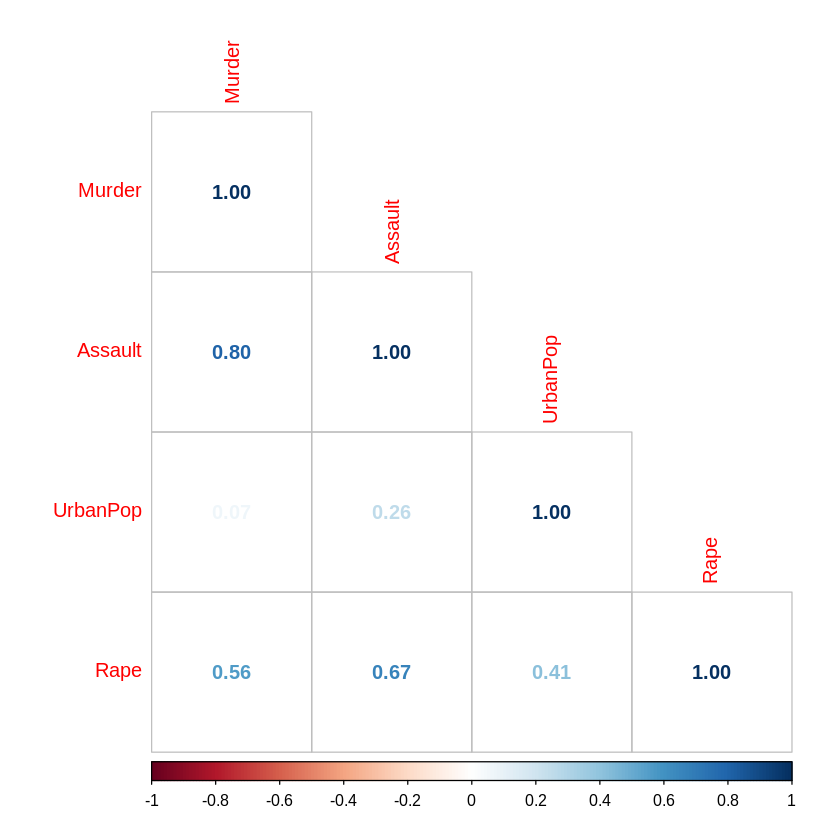

In [ ]:
corrplot(cor(USArrests), method = "number",type = "lower")

In [ ]:
p1<-princomp(df)

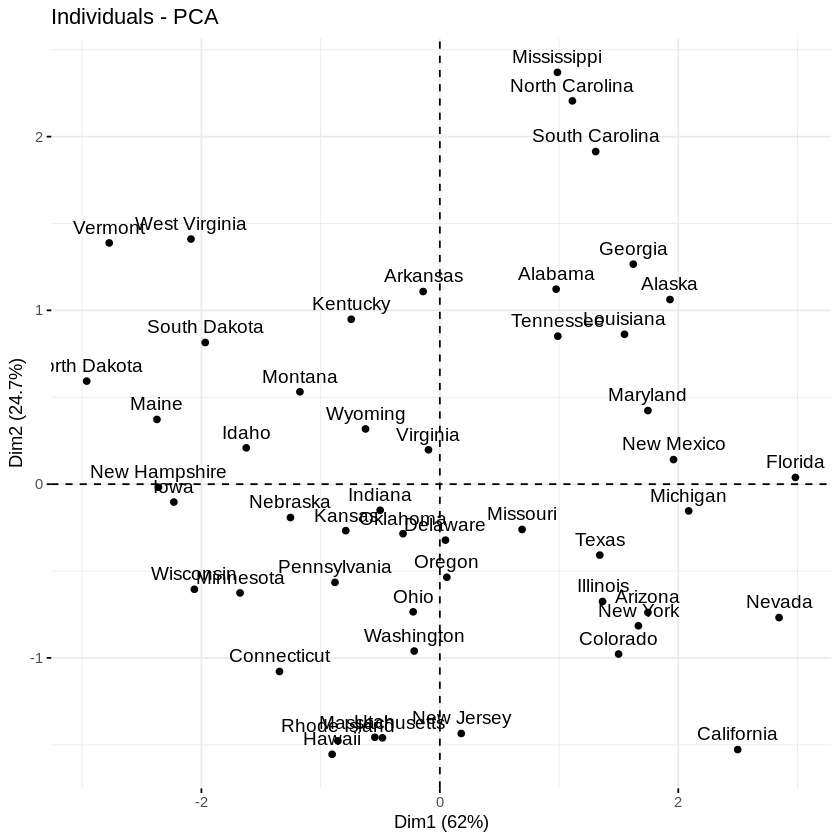

In [ ]:
fviz_pca_ind(p1)

In [ ]:
install.packages("rgl")
library(rgl)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message in rgl.init(initValue, onlyNULL):
“RGL: unable to open X11 display”
Warning message:
“'rgl.init' failed, running with 'rgl.useNULL = TRUE'.”


In [ ]:
plot3d(p1$scores[,1:3])

In [ ]:
install.packages("scatterplot3d")
library("scatterplot3d")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



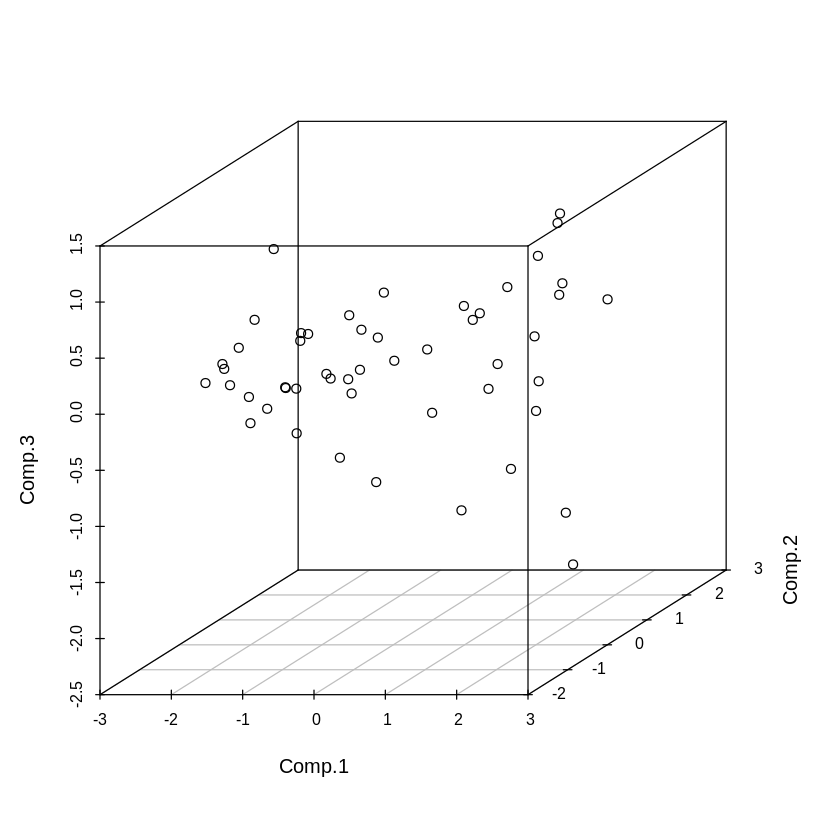

In [ ]:
scatterplot3d(p1$scores[,1:3])

Distancia Euclideana

In [ ]:
set.seed(123)
crime <- sample(1:50,10)
crime_1 <- USArrests[crime,]
head(crime_1)

,Murder,Assault,UrbanPop,Rape
,<dbl>,<int>,<int>,<dbl>
New Mexico,11.4,285,70,32.1
Iowa,2.2,56,57,11.3
Indiana,7.2,113,65,21.0
Arizona,8.1,294,80,31.0
Tennessee,13.2,188,59,26.9
Texas,12.7,201,80,25.5


In [ ]:
dist.eucl <- dist(crime_1, method = "euclidean")
head(dist.eucl)

[1] 230.49356 172.48145  13.89604  97.77668  84.86018 126.23427

In [ ]:
round(as.matrix(dist.eucl)[1:4, 1:4], 1)

,New Mexico,Iowa,Indiana,Arizona
New Mexico,0.0,230.5,172.5,13.9
Iowa,230.5,0.0,58.6,240.0
Indiana,172.5,58.6,0.0,181.9
Arizona,13.9,240.0,181.9,0.0


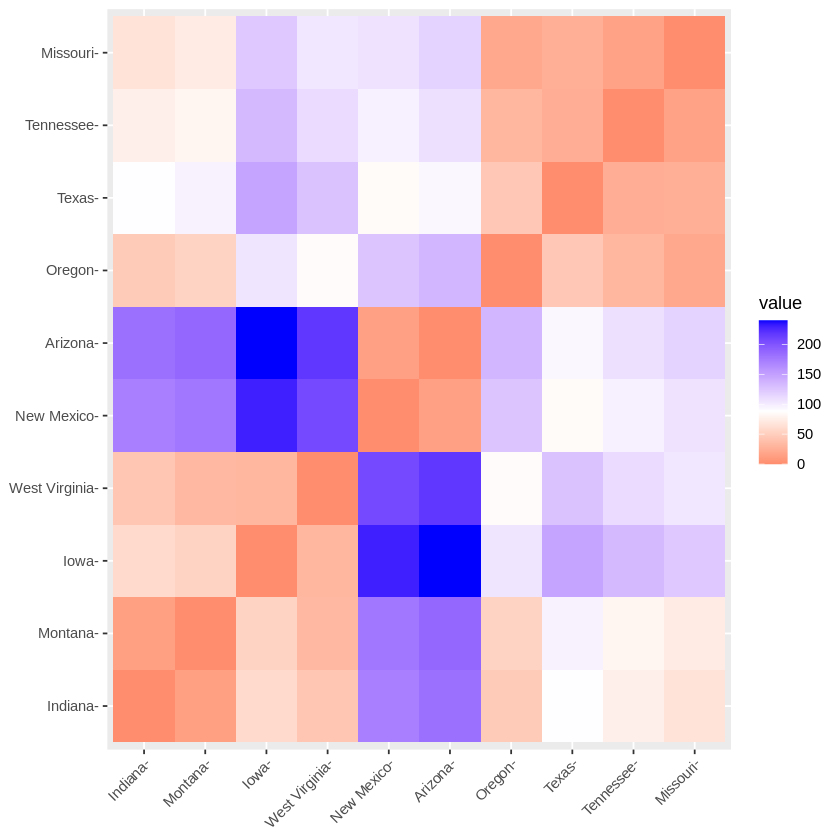

In [ ]:
fviz_dist(dist.eucl)

# K-medias

In [ ]:
k2 <- kmeansruns(df, krange=2, runs=100)

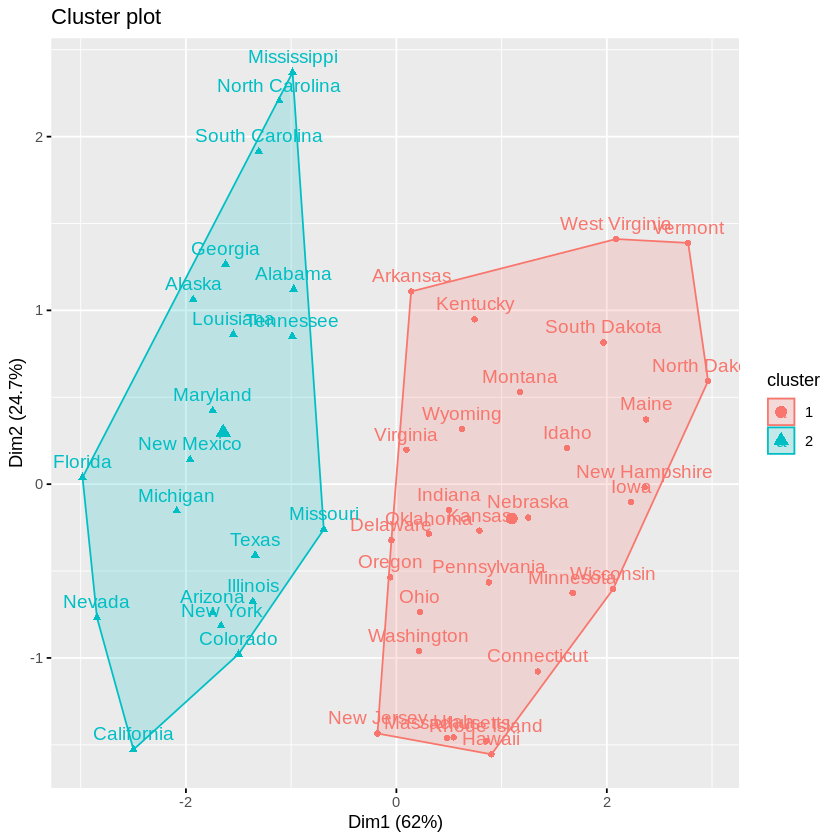

In [ ]:
fviz_cluster(k2,data=df)

In [ ]:
k2

K-means clustering with 2 clusters of sizes 30, 20

Cluster means:
     Murder    Assault   UrbanPop       Rape
1 -0.669956 -0.6758849 -0.1317235 -0.5646433
2  1.004934  1.0138274  0.1975853  0.8469650

Clustering vector:
       Alabama         Alaska        Arizona       Arkansas     California 
             2              2              2              1              2 
      Colorado    Connecticut       Delaware        Florida        Georgia 
             2              1              1              2              2 
        Hawaii          Idaho       Illinois        Indiana           Iowa 
             1              1              2              1              1 
        Kansas       Kentucky      Louisiana          Maine       Maryland 
             1              1              2              1              2 
 Massachusetts       Michigan      Minnesota    Mississippi       Missouri 
             1              2              1              2              2 
       Montana    

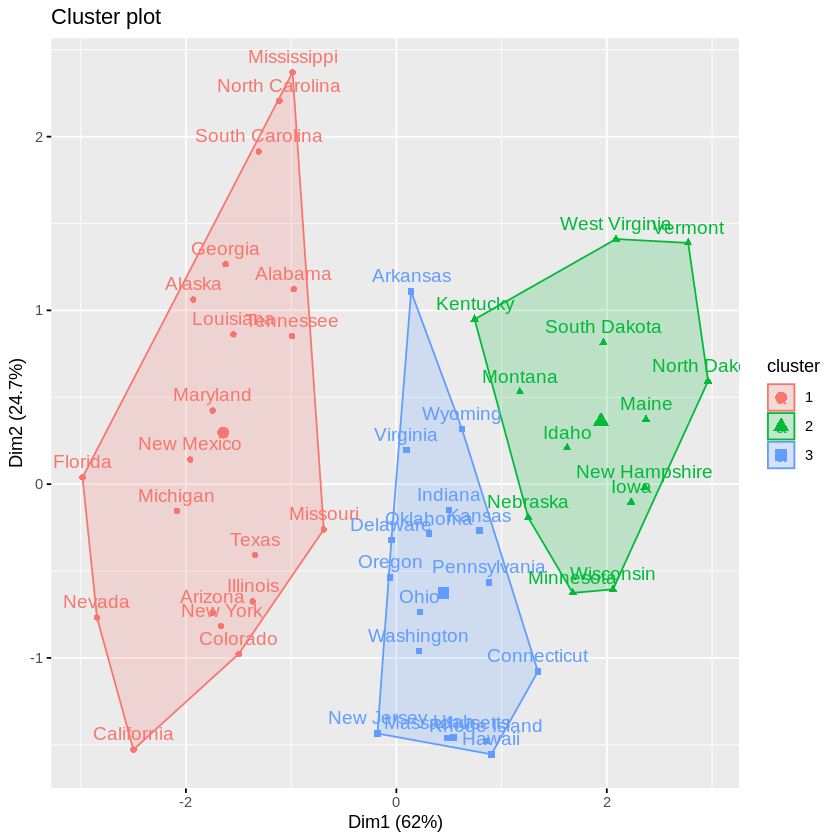

In [ ]:
k3 <- kmeansruns(df, krange=3, runs=100)
fviz_cluster(k3,data=df)

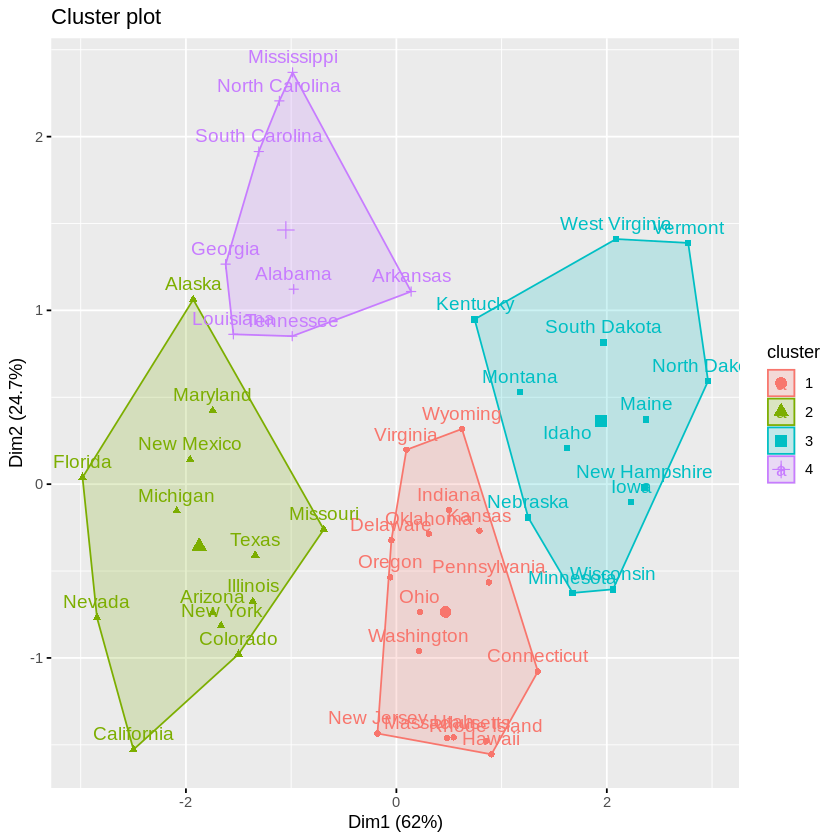

In [ ]:
k4 <- kmeansruns(df, krange=4, runs=100)
fviz_cluster(k4,data=df)

Evaluamos el número de clusters

Método del codo

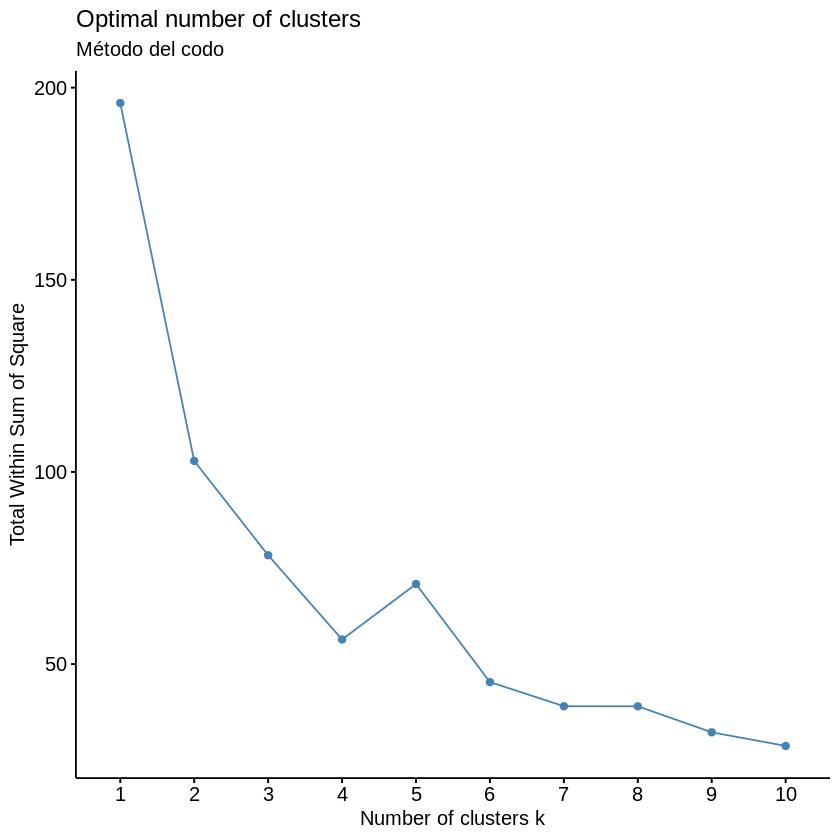

In [ ]:
fviz_nbclust(df,kmeans,method = "wss")+labs(subtitle = "Método del codo")

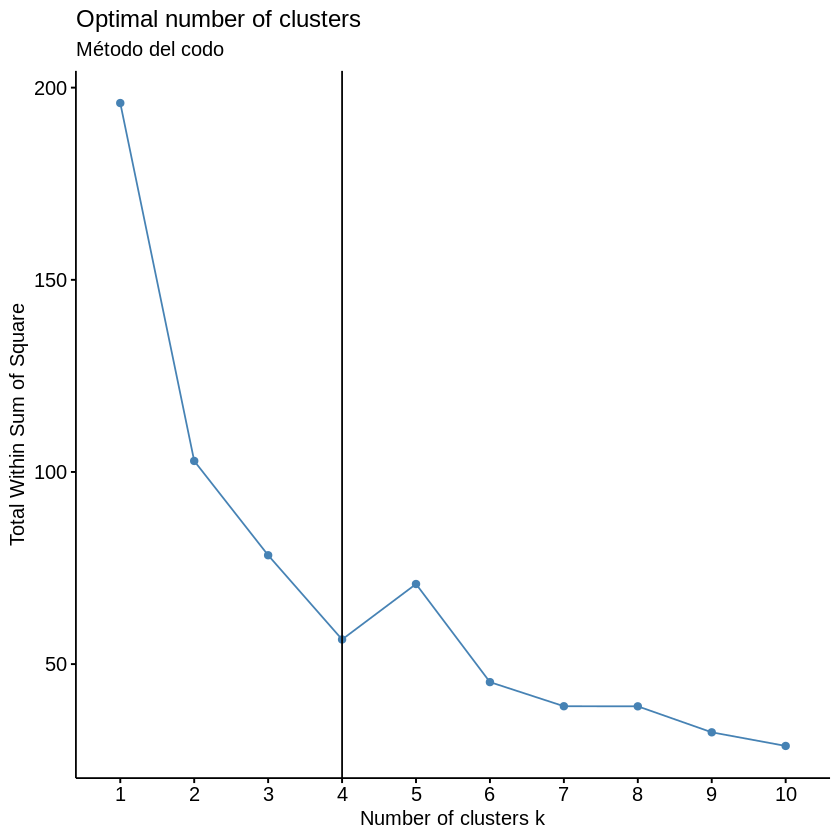

In [ ]:
fviz_nbclust(df,kmeans,method = "wss")+labs(subtitle = "Método del codo")+geom_vline(xintercept = 4)

Método de la silueta

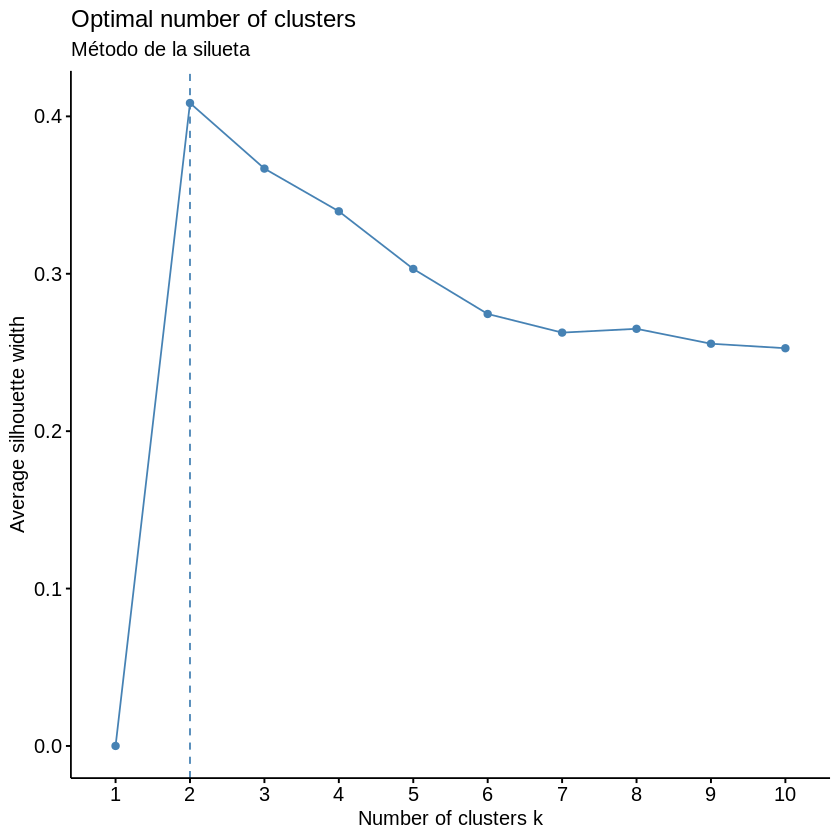

In [ ]:
fviz_nbclust(df,kmeans,method="silhouette")+labs(subtitle = "Método de la silueta")

Gap statistic

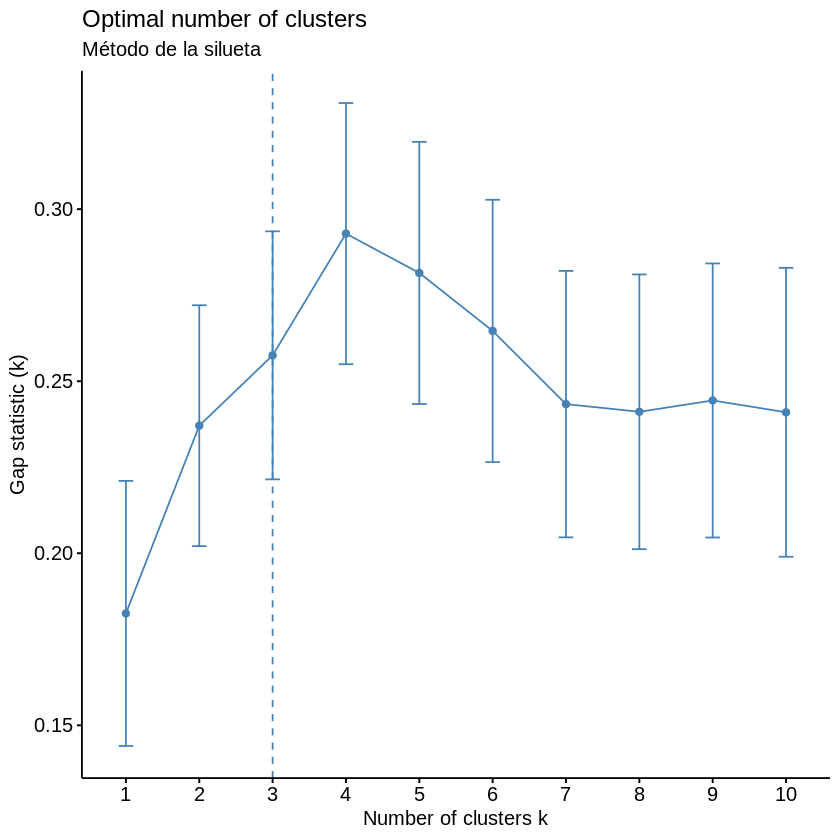

In [ ]:
set.seed(123)
fviz_nbclust(df,kmeans,nstart=25,method="gap_stat")+labs(subtitle = "Método gap stat")

Método completo

*** : The Hubert index is a graphical method of determining the number of clusters.
                In the plot of Hubert index, we seek a significant knee that corresponds to a 
                significant increase of the value of the measure i.e the significant peak in Hubert
                index second differences plot. 
 


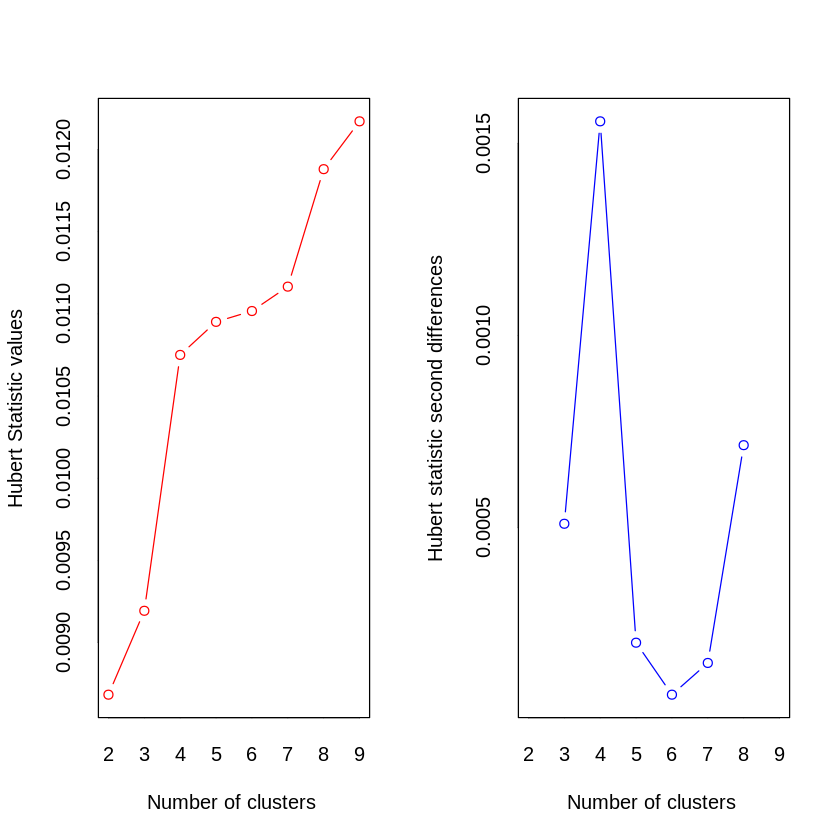

*** : The D index is a graphical method of determining the number of clusters. 
                In the plot of D index, we seek a significant knee (the significant peak in Dindex
                second differences plot) that corresponds to a significant increase of the value of
                the measure. 
 
******************************************************************* 
* Among all indices:                                                
* 9 proposed 2 as the best number of clusters 
* 4 proposed 3 as the best number of clusters 
* 6 proposed 4 as the best number of clusters 
* 2 proposed 5 as the best number of clusters 
* 1 proposed 8 as the best number of clusters 
* 1 proposed 9 as the best number of clusters 

                   ***** Conclusion *****                            
 
* According to the majority rule, the best number of clusters is  2 
 
 
******************************************************************* 


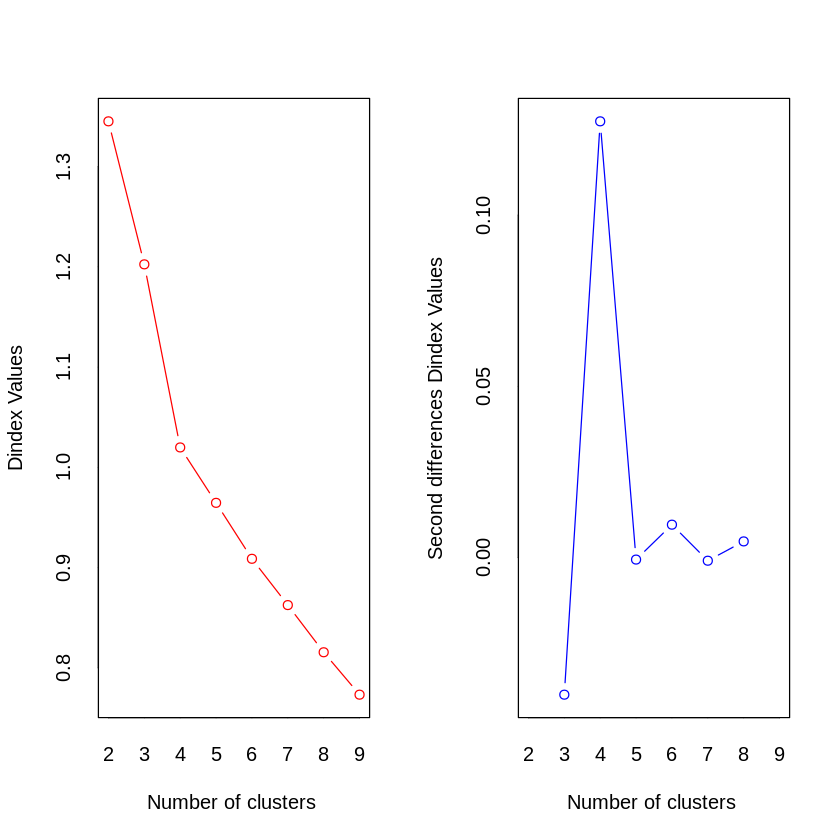

In [ ]:
res.nbclust<- NbClust(df, distance = "euclidean", min.nc = 2, max.nc = 9, method = "complete", index = "all",)

In [ ]:
factoextra::fviz_nbclust(res.nbclust)+theme_minimal()+ggtitle("Número óptimo de clusters por NbClust")+theme_classic()

ERROR: ignored

Verificamos que los clusters sean estables

In [ ]:
cf2 <- clusterboot(df,B=100,bootmethod = c("jitter","boot"),clustermethod=kmeansCBI,krange=2,seed = 123) #con 2 clusters

jitter 1 
jitter 2 
jitter 3 
jitter 4 
jitter 5 
jitter 6 
jitter 7 
jitter 8 
jitter 9 
jitter 10 
jitter 11 
jitter 12 
jitter 13 
jitter 14 
jitter 15 
jitter 16 
jitter 17 
jitter 18 
jitter 19 
jitter 20 
jitter 21 
jitter 22 
jitter 23 
jitter 24 
jitter 25 
jitter 26 
jitter 27 
jitter 28 
jitter 29 
jitter 30 
jitter 31 
jitter 32 
jitter 33 
jitter 34 
jitter 35 
jitter 36 
jitter 37 
jitter 38 
jitter 39 
jitter 40 
jitter 41 
jitter 42 
jitter 43 
jitter 44 
jitter 45 
jitter 46 
jitter 47 
jitter 48 
jitter 49 
jitter 50 
jitter 51 
jitter 52 
jitter 53 
jitter 54 
jitter 55 
jitter 56 
jitter 57 
jitter 58 
jitter 59 
jitter 60 
jitter 61 
jitter 62 
jitter 63 
jitter 64 
jitter 65 
jitter 66 
jitter 67 
jitter 68 
jitter 69 
jitter 70 
jitter 71 
jitter 72 
jitter 73 
jitter 74 
jitter 75 
jitter 76 
jitter 77 
jitter 78 
jitter 79 
jitter 80 
jitter 81 
jitter 82 
jitter 83 
jitter 84 
jitter 85 
jitter 86 
jitter 87 
jitter 88 
jitter 89 
jitter 90 
jitter 91 
jitter 9

In [ ]:
print(cf2)

* Cluster stability assessment *
Cluster method:  kmeans 
Full clustering results are given as parameter result
of the clusterboot object, which also provides further statistics
of the resampling results.
Number of resampling runs:  100 

Number of clusters found in data:  2 

 Clusterwise Jaccard jittering mean:
[1] 1 1
dissolved:
[1] 0 0
recovered:
[1] 100 100
 Clusterwise Jaccard bootstrap (omitting multiple points) mean:
[1] 0.9855556 0.9880336
dissolved:
[1] 1 1
recovered:
[1] 97 99


In [ ]:
cf3 <- clusterboot(df,B=100,bootmethod = c("jitter","boot"),clustermethod=kmeansCBI,krange=3,seed = 123) #con 3 clusters

jitter 1 
jitter 2 
jitter 3 
jitter 4 
jitter 5 
jitter 6 
jitter 7 
jitter 8 
jitter 9 
jitter 10 
jitter 11 
jitter 12 
jitter 13 
jitter 14 
jitter 15 
jitter 16 
jitter 17 
jitter 18 
jitter 19 
jitter 20 
jitter 21 
jitter 22 
jitter 23 
jitter 24 
jitter 25 
jitter 26 
jitter 27 
jitter 28 
jitter 29 
jitter 30 
jitter 31 
jitter 32 
jitter 33 
jitter 34 
jitter 35 
jitter 36 
jitter 37 
jitter 38 
jitter 39 
jitter 40 
jitter 41 
jitter 42 
jitter 43 
jitter 44 
jitter 45 
jitter 46 
jitter 47 
jitter 48 
jitter 49 
jitter 50 
jitter 51 
jitter 52 
jitter 53 
jitter 54 
jitter 55 
jitter 56 
jitter 57 
jitter 58 
jitter 59 
jitter 60 
jitter 61 
jitter 62 
jitter 63 
jitter 64 
jitter 65 
jitter 66 
jitter 67 
jitter 68 
jitter 69 
jitter 70 
jitter 71 
jitter 72 
jitter 73 
jitter 74 
jitter 75 
jitter 76 
jitter 77 
jitter 78 
jitter 79 
jitter 80 
jitter 81 
jitter 82 
jitter 83 
jitter 84 
jitter 85 
jitter 86 
jitter 87 
jitter 88 
jitter 89 
jitter 90 
jitter 91 
jitter 9

In [ ]:
print(cf3)

* Cluster stability assessment *
Cluster method:  kmeans 
Full clustering results are given as parameter result
of the clusterboot object, which also provides further statistics
of the resampling results.
Number of resampling runs:  100 

Number of clusters found in data:  3 

 Clusterwise Jaccard jittering mean:
[1] 0.839000 0.765185 0.774500
dissolved:
[1]  0 36 10
recovered:
[1] 54 54 54
 Clusterwise Jaccard bootstrap (omitting multiple points) mean:
[1] 0.7800697 0.6661633 0.6698572
dissolved:
[1]  5 37 26
recovered:
[1] 47 41 38


In [ ]:
cf4 <- clusterboot(df,B=100,bootmethod = c("jitter","boot"),clustermethod=kmeansCBI,krange=4,seed = 123) #con 4 clusters
print(cf4)

jitter 1 
jitter 2 
jitter 3 
jitter 4 
jitter 5 
jitter 6 
jitter 7 
jitter 8 
jitter 9 
jitter 10 
jitter 11 
jitter 12 
jitter 13 
jitter 14 
jitter 15 
jitter 16 
jitter 17 
jitter 18 
jitter 19 
jitter 20 
jitter 21 
jitter 22 
jitter 23 
jitter 24 
jitter 25 
jitter 26 
jitter 27 
jitter 28 
jitter 29 
jitter 30 
jitter 31 
jitter 32 
jitter 33 
jitter 34 
jitter 35 
jitter 36 
jitter 37 
jitter 38 
jitter 39 
jitter 40 
jitter 41 
jitter 42 
jitter 43 
jitter 44 
jitter 45 
jitter 46 
jitter 47 
jitter 48 
jitter 49 
jitter 50 
jitter 51 
jitter 52 
jitter 53 
jitter 54 
jitter 55 
jitter 56 
jitter 57 
jitter 58 
jitter 59 
jitter 60 
jitter 61 
jitter 62 
jitter 63 
jitter 64 
jitter 65 
jitter 66 
jitter 67 
jitter 68 
jitter 69 
jitter 70 
jitter 71 
jitter 72 
jitter 73 
jitter 74 
jitter 75 
jitter 76 
jitter 77 
jitter 78 
jitter 79 
jitter 80 
jitter 81 
jitter 82 
jitter 83 
jitter 84 
jitter 85 
jitter 86 
jitter 87 
jitter 88 
jitter 89 
jitter 90 
jitter 91 
jitter 9

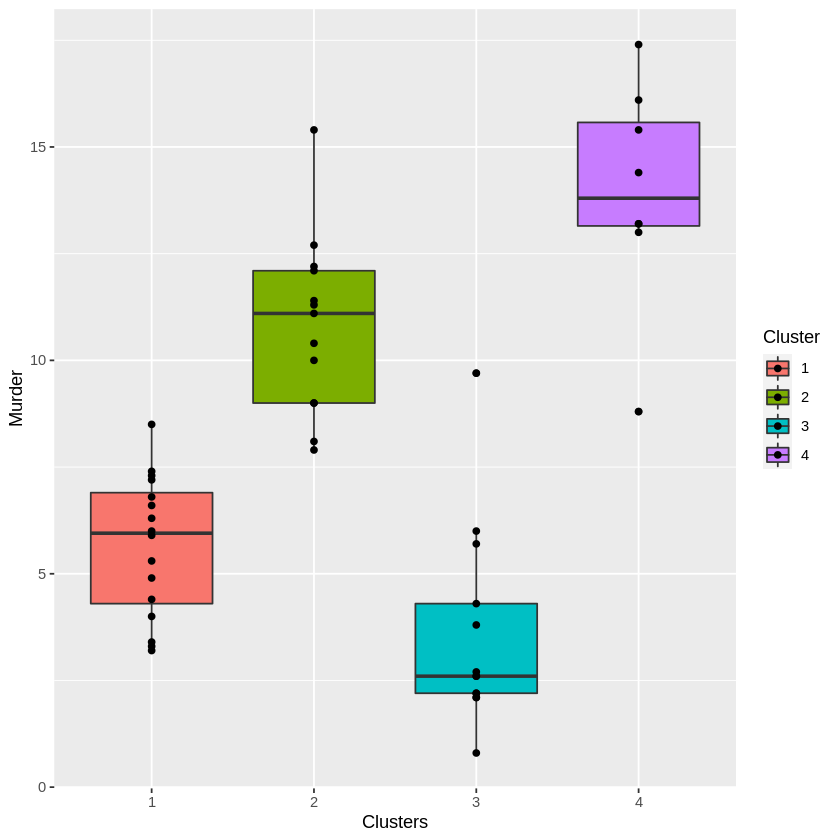

In [ ]:
USArrests %>% ggplot(aes(x=factor(k4$cluster), y=Murder, fill=factor(k4$cluster)))+geom_boxplot()+geom_point()+xlab("Clusters")+labs(fill="Cluster")

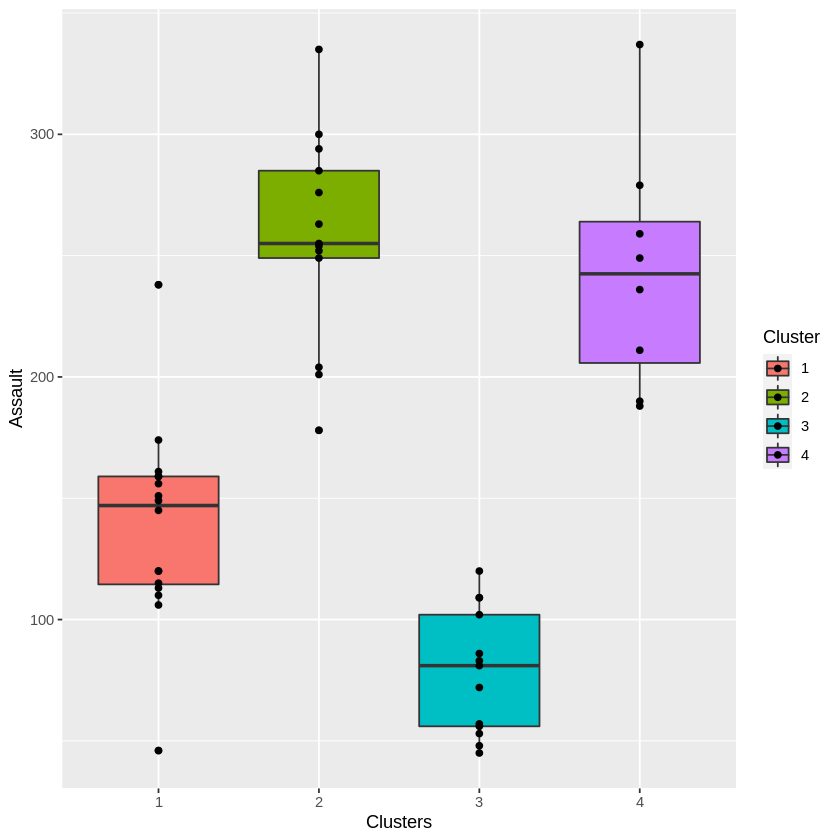

In [ ]:
USArrests %>% ggplot(aes(x=factor(k4$cluster), y=Assault, fill=factor(k4$cluster)))+geom_boxplot()+geom_point()+xlab("Clusters")+labs(fill="Cluster")

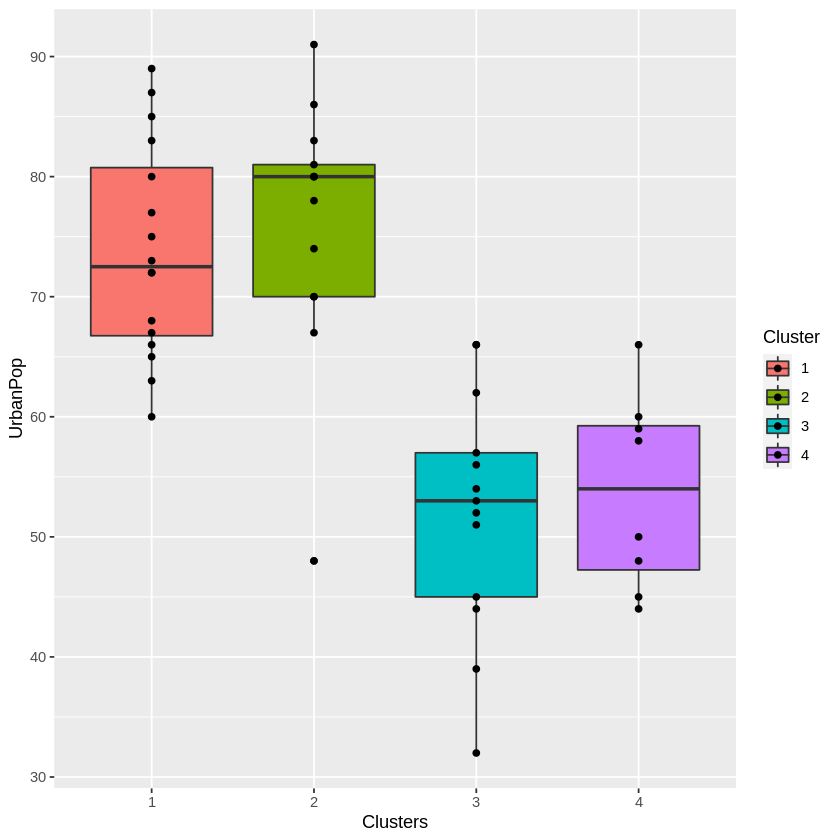

In [ ]:
USArrests %>% ggplot(aes(x=factor(k4$cluster), y=UrbanPop, fill=factor(k4$cluster)))+geom_boxplot()+geom_point()+xlab("Clusters")+labs(fill="Cluster")

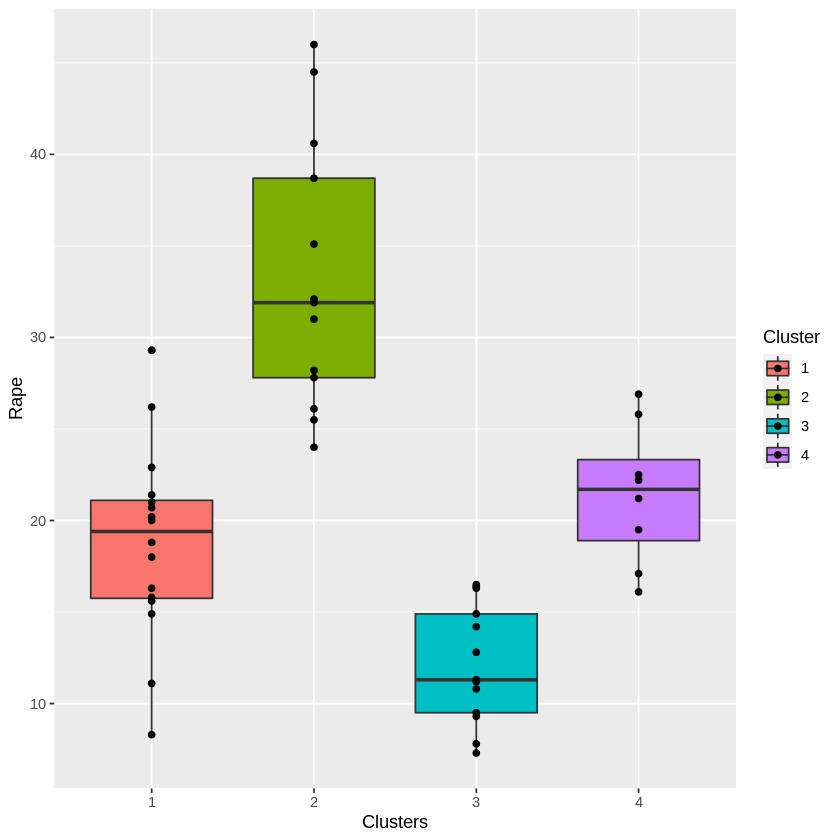

In [ ]:
USArrests %>% ggplot(aes(x=factor(k4$cluster), y=Rape, fill=factor(k4$cluster)))+geom_boxplot()+geom_point()+xlab("Clusters")+labs(fill="Cluster")

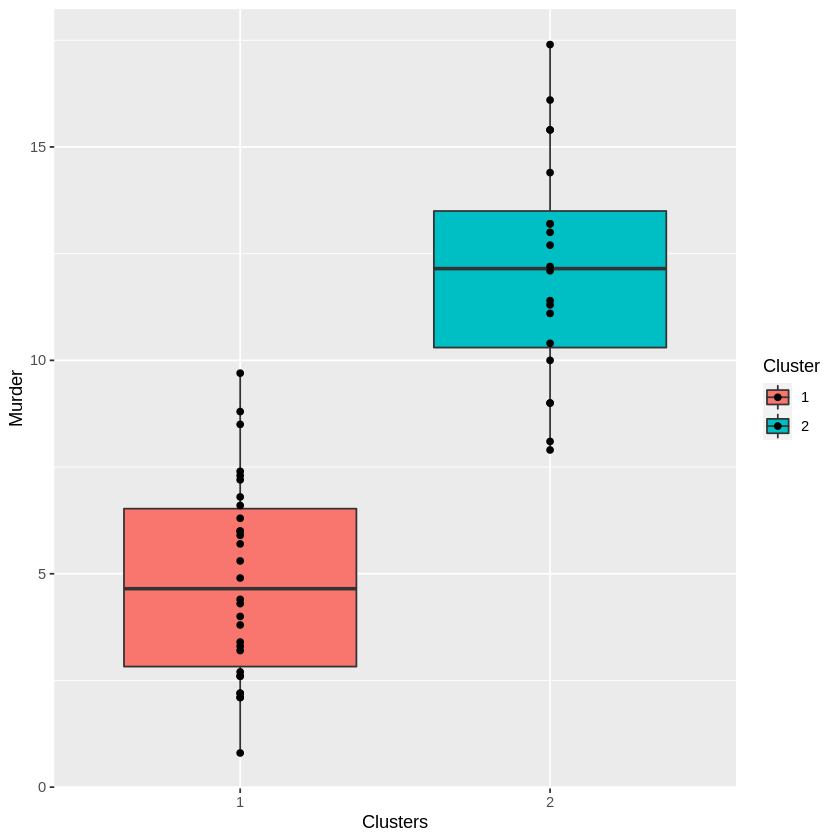

In [ ]:
USArrests %>% ggplot(aes(x=factor(k2$cluster), y=Murder, fill=factor(k2$cluster)))+geom_boxplot()+geom_point()+xlab("Clusters")+labs(fill="Cluster")

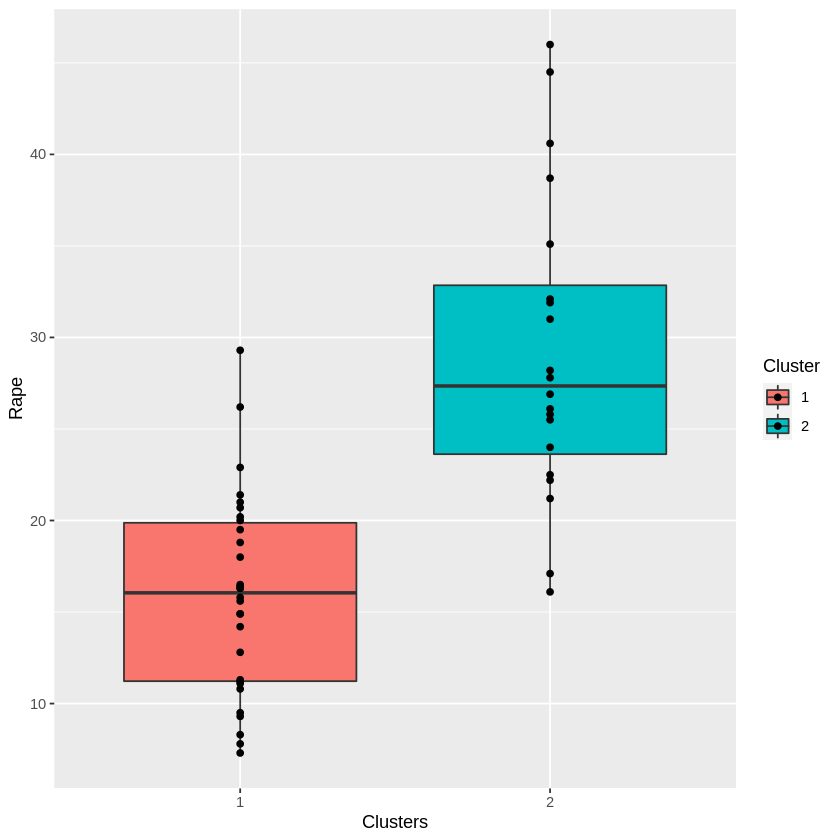

In [ ]:
USArrests %>% ggplot(aes(x=factor(k2$cluster), y=Rape, fill=factor(k2$cluster)))+geom_boxplot()+geom_point()+xlab("Clusters")+labs(fill="Cluster")

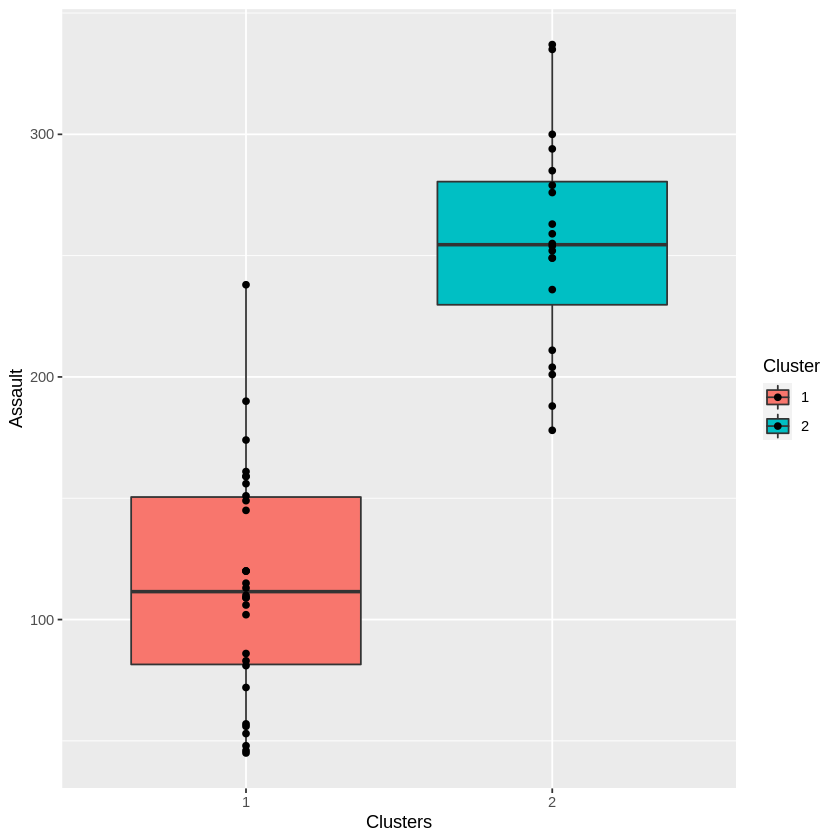

In [ ]:
USArrests %>% ggplot(aes(x=factor(k2$cluster), y=Assault, fill=factor(k2$cluster)))+geom_boxplot()+geom_point()+xlab("Clusters")+labs(fill="Cluster")

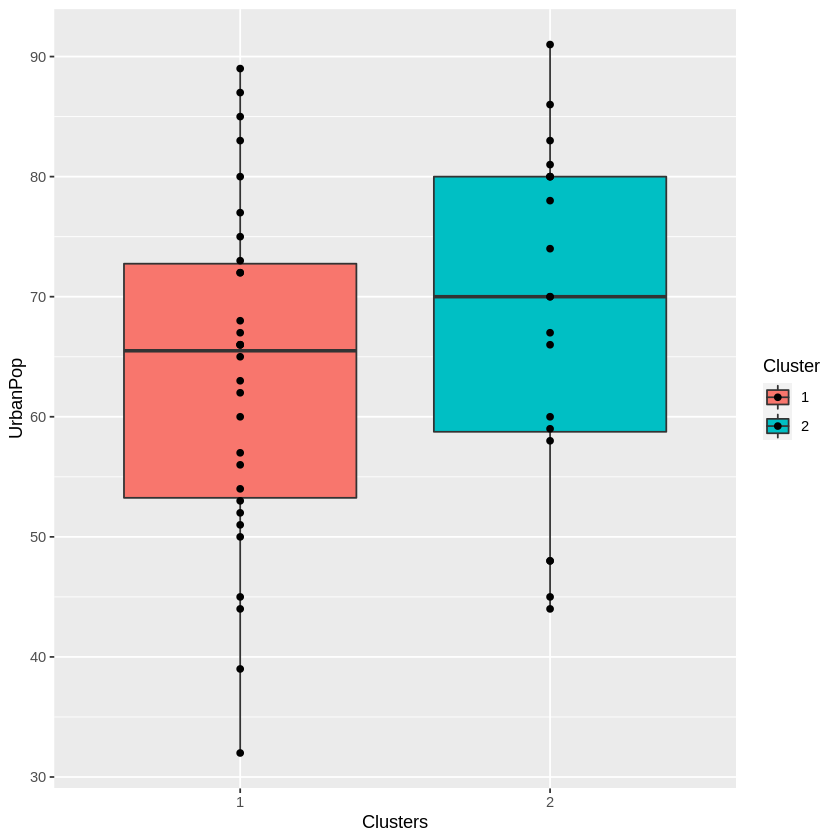

In [ ]:
USArrests %>% ggplot(aes(x=factor(k2$cluster), y=UrbanPop, fill=factor(k2$cluster)))+geom_boxplot()+geom_point()+xlab("Clusters")+labs(fill="Cluster")

De acuerdo a lo que querramos puede ser suficientes 2 clusters o no.
Si descartamos el usar 2 clusters:

*** : The Hubert index is a graphical method of determining the number of clusters.
                In the plot of Hubert index, we seek a significant knee that corresponds to a 
                significant increase of the value of the measure i.e the significant peak in Hubert
                index second differences plot. 
 


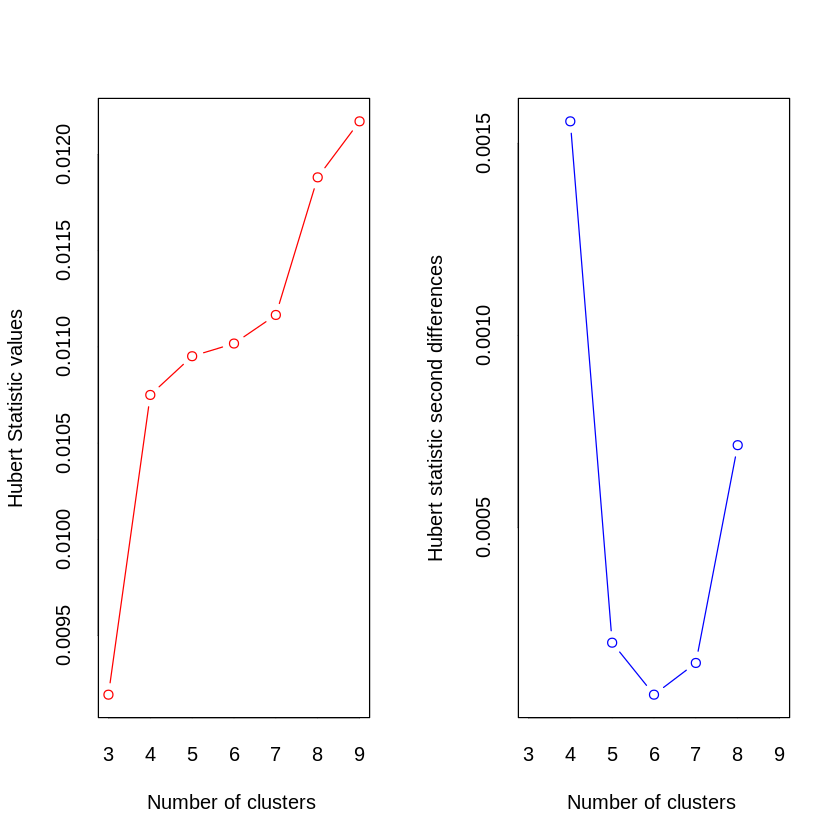

*** : The D index is a graphical method of determining the number of clusters. 
                In the plot of D index, we seek a significant knee (the significant peak in Dindex
                second differences plot) that corresponds to a significant increase of the value of
                the measure. 
 
******************************************************************* 
* Among all indices:                                                
* 9 proposed 3 as the best number of clusters 
* 10 proposed 4 as the best number of clusters 
* 2 proposed 5 as the best number of clusters 
* 1 proposed 8 as the best number of clusters 
* 1 proposed 9 as the best number of clusters 

                   ***** Conclusion *****                            
 
* According to the majority rule, the best number of clusters is  4 
 
 
******************************************************************* 


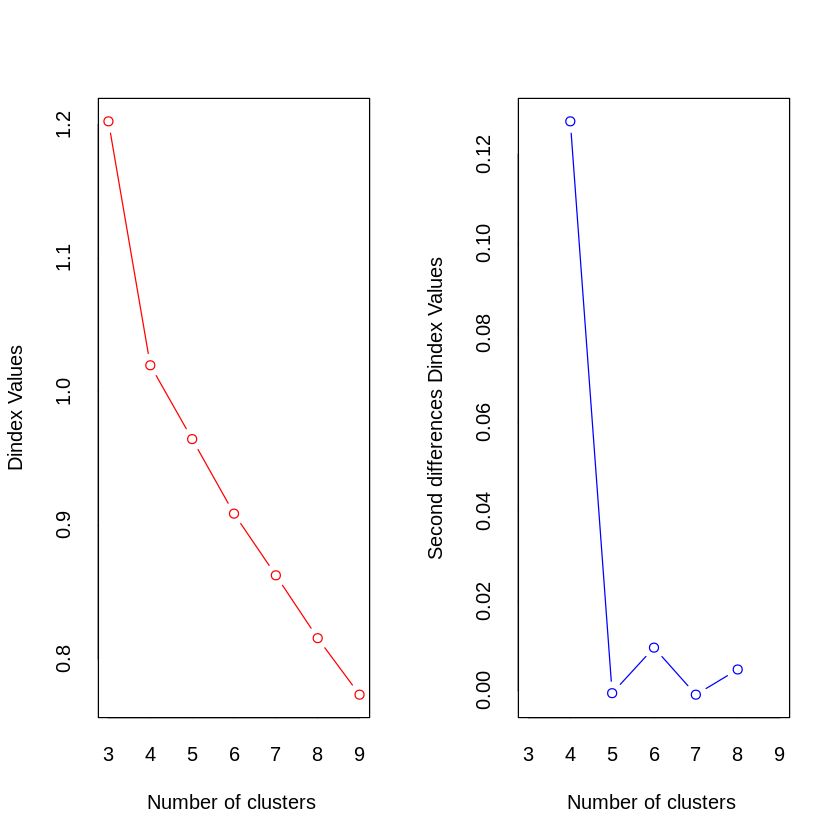

In [ ]:
set.seed=123
res.nbclust<- NbClust(df, distance = "euclidean", min.nc = 3, max.nc = 9, method = "complete", index = "all")

Agregar la clasificación a los datos originales

In [ ]:
df_member <- cbind(df, clust = k4$cluster)
head(df_member,10)

,Murder,Assault,UrbanPop,Rape,clust
Alabama,1.24256408,0.7828393,-0.5209066,-0.003416473,4
Alaska,0.50786248,1.1068225,-1.2117642,2.484202941,2
Arizona,0.07163341,1.4788032,0.9989801,1.042878388,2
Arkansas,0.23234938,0.2308680,-1.0735927,-0.184916602,4
California,0.27826823,1.2628144,1.7589234,2.067820292,2
Colorado,0.02571456,0.3988593,0.8608085,1.864967207,2
Connecticut,-1.03041900,-0.7290821,0.7917228,-1.081740768,1
Delaware,-0.43347395,0.8068381,0.4462940,-0.579946294,1
Florida,1.74767144,1.9707777,0.9989801,1.138966691,2
Georgia,2.20685994,0.4828549,-0.3827351,0.487701523,4


Otra visualización

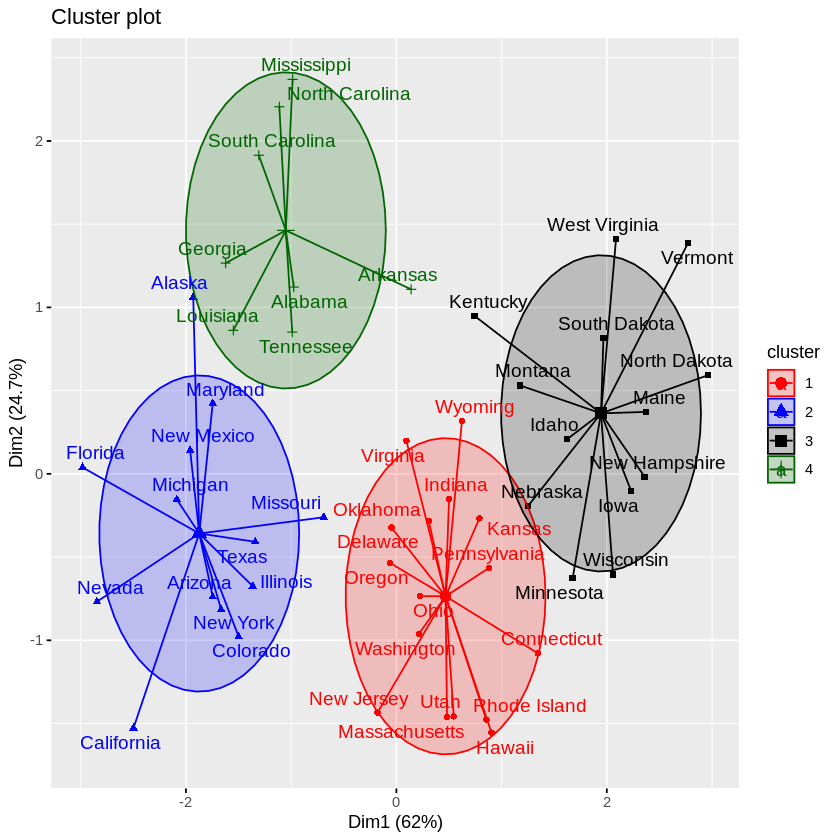

In [ ]:
fviz_cluster(k4, data = df,
             palette=c("red", "blue", "black", "darkgreen"),
             ellipse.type = "euclid",
             star.plot = T,
             repel = T,
             ggtheme = theme())

In [ ]:
library(ggplot2)
crimes <- data.frame(state = tolower(rownames(USArrests)), USArrests)
library(reshape2) # for melt
crimesm <- melt(crimes, id = 1)
install.packages("maps")
install.packages("mapproj")
library(maps)
library(mapproj)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



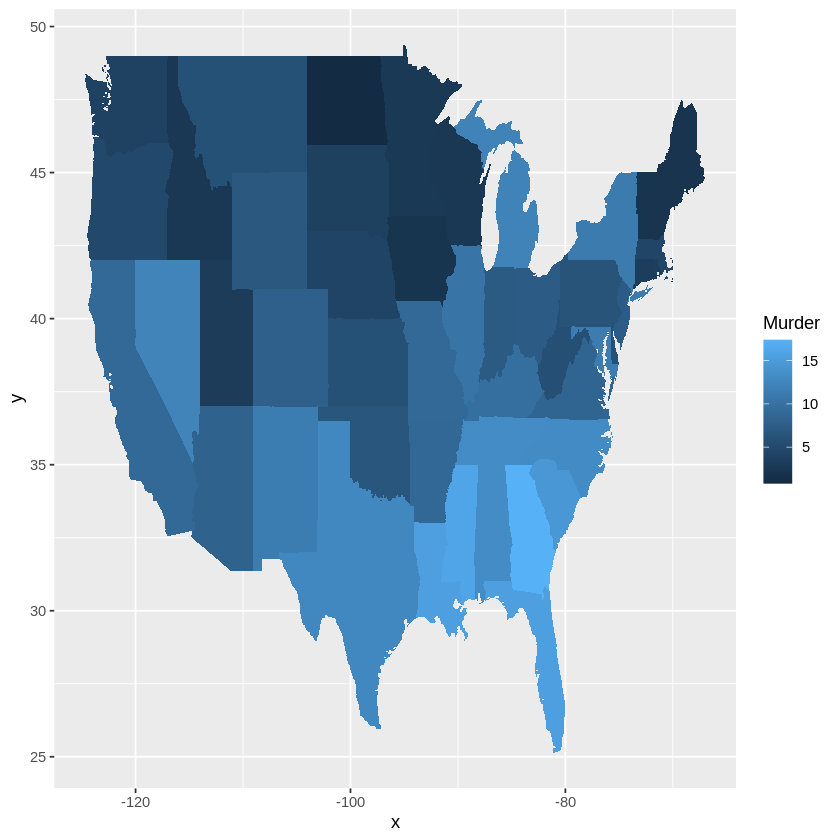

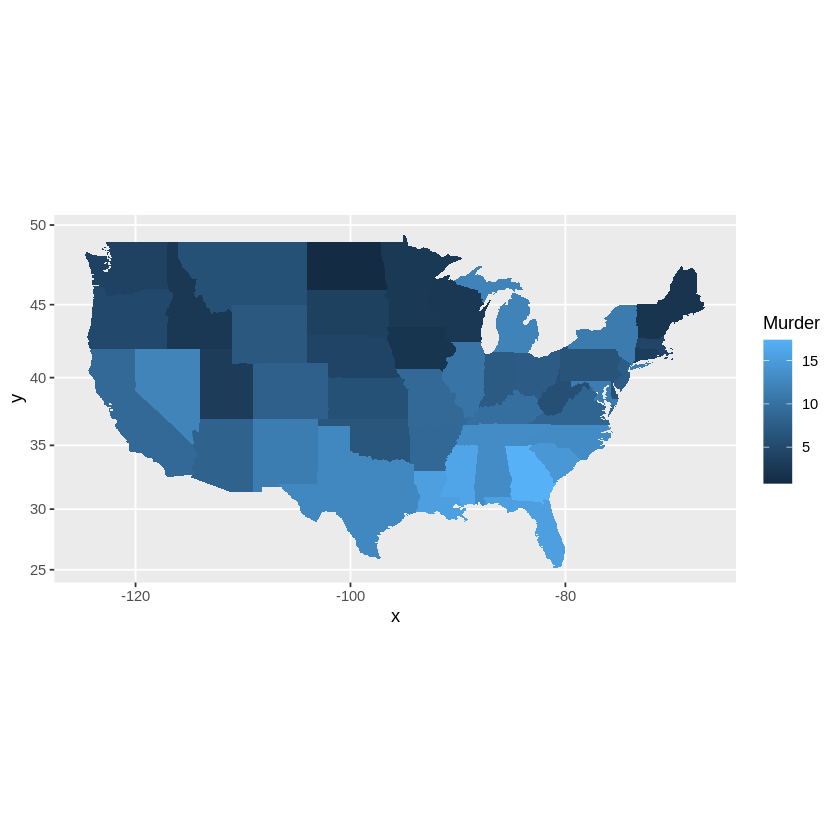

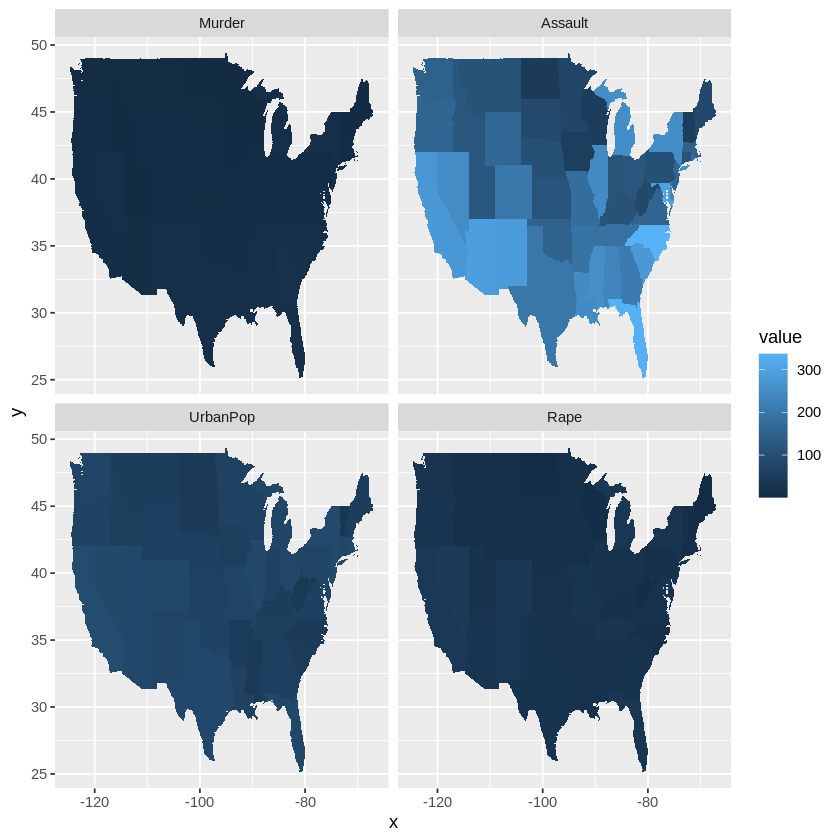

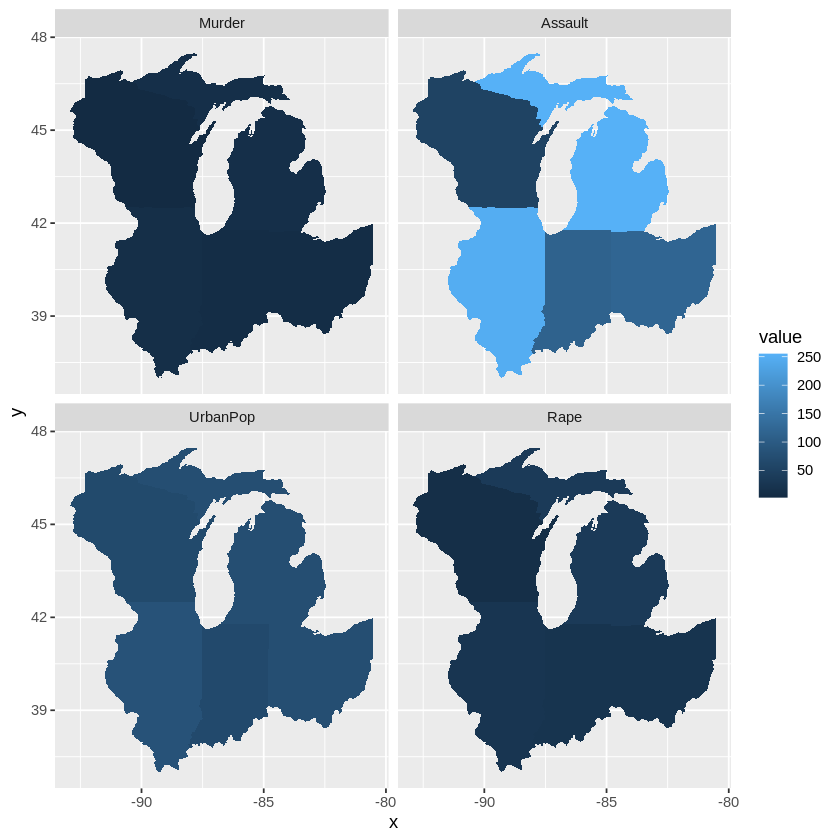

In [ ]:
states_map <- map_data("state")
ggplot(crimes, aes(map_id = state)) + geom_map(aes(fill = Murder), map = states_map) + expand_limits(x = states_map$long, y = states_map$lat)
last_plot() + coord_map()
ggplot(crimesm, aes(map_id = state)) + geom_map(aes(fill = value), map = states_map) + expand_limits(x = states_map$long, y = states_map$lat) + facet_wrap( ~ variable)
great_lakes_states = c('michigan', 'illinois', 'ohio', 'wisconsin', 'indiana')
great_lakes_map = subset(states_map, region %in% great_lakes_states)
ggplot(subset(crimesm, state %in% great_lakes_states), aes(map_id = state)) + geom_map(aes(fill = value), map = great_lakes_map) + expand_limits(x=great_lakes_map$long, y=great_lakes_map$lat) + facet_wrap( ~ variable)

In [ ]:
columnas <- data.frame(state = tolower(rownames(df_member)), df_member)
columnas

,state,Murder,Assault,UrbanPop,Rape,clust
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Alabama,alabama,1.24256408,0.78283935,-0.52090661,-0.003416473,4
Alaska,alaska,0.50786248,1.10682252,-1.21176419,2.484202941,2
Arizona,arizona,0.07163341,1.47880321,0.99898006,1.042878388,2
Arkansas,arkansas,0.23234938,0.23086801,-1.07359268,-0.184916602,4
California,california,0.27826823,1.26281442,1.75892340,2.067820292,2
Colorado,colorado,0.02571456,0.39885929,0.86080854,1.864967207,2
Connecticut,connecticut,-1.03041900,-0.72908214,0.79172279,-1.081740768,1
Delaware,delaware,-0.43347395,0.80683810,0.44629400,-0.579946294,1
Florida,florida,1.74767144,1.97077766,0.99898006,1.138966691,2


In [ ]:
crimesm2<-melt(columnas, id = 1)

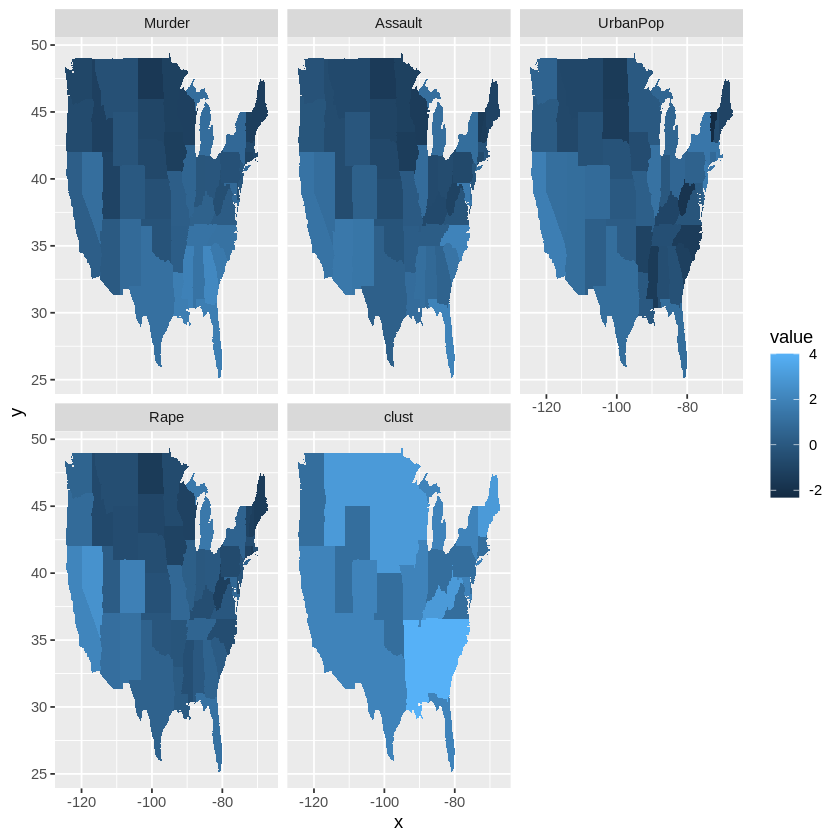

In [ ]:
ggplot(crimesm2, aes(map_id = state)) + geom_map(aes(fill = value), map = states_map) + expand_limits(x = states_map$long, y = states_map$lat) + facet_wrap( ~ variable)

# Clustering jerárquico

In [ ]:
d<-dist(df,method = "euclidean")
d

                 Alabama    Alaska   Arizona  Arkansas California  Colorado
Alaska         2.7037541                                                   
Arizona        2.2935197 2.7006429                                         
Arkansas       1.2898102 2.8260386 2.7177583                               
California     3.2631104 3.0125415 1.3104842 3.7636409                     
Colorado       2.6510673 2.3265187 1.3650307 2.8310512  1.2876185          
Connecticut    3.2152975 4.7399125 3.2628575 2.6076395  4.0663898 3.3279920
Delaware       2.0192927 3.6213633 1.9093696 1.8003239  3.0737852 2.5547456
Florida        2.2981353 2.9967642 1.7493928 3.3721968  2.0250039 2.4458600
Georgia        1.1314351 2.8194388 2.7871963 2.2117614  3.3780585 2.8649105
Hawaii         3.3885300 4.5301340 3.2621208 2.9723097  3.6589083 2.8233524
Idaho          2.9146623 4.0580555 3.5210071 1.7687255  4.4879436 3.4767685
Illinois       1.8734993 3.2670626 1.0825512 2.4626424  1.9117469 1.7898322
Indiana     

In [ ]:
df

,Murder,Assault,UrbanPop,Rape
Alabama,1.24256408,0.78283935,-0.52090661,-0.003416473
Alaska,0.50786248,1.10682252,-1.21176419,2.484202941
Arizona,0.07163341,1.47880321,0.99898006,1.042878388
Arkansas,0.23234938,0.23086801,-1.07359268,-0.184916602
California,0.27826823,1.26281442,1.75892340,2.067820292
Colorado,0.02571456,0.39885929,0.86080854,1.864967207
Connecticut,-1.03041900,-0.72908214,0.79172279,-1.081740768
Delaware,-0.43347395,0.80683810,0.44629400,-0.579946294
Florida,1.74767144,1.97077766,0.99898006,1.138966691
Georgia,2.20685994,0.48285493,-0.38273510,0.487701523


Clustering jerárquico con liga completa

In [ ]:
hc1 <- hclust(d,method = "complete")

In [ ]:
hc1


Call:
hclust(d = d, method = "complete")

Cluster method   : complete 
Distance         : euclidean 
Number of objects: 50 


Clustering jerárquico con liga completa

In [ ]:
hc2 <- hclust(d,method = "ward.D2")

In [ ]:
hc2


Call:
hclust(d = d, method = "ward.D2")

Cluster method   : ward.D2 
Distance         : euclidean 
Number of objects: 50 


Hacemos el dendograma

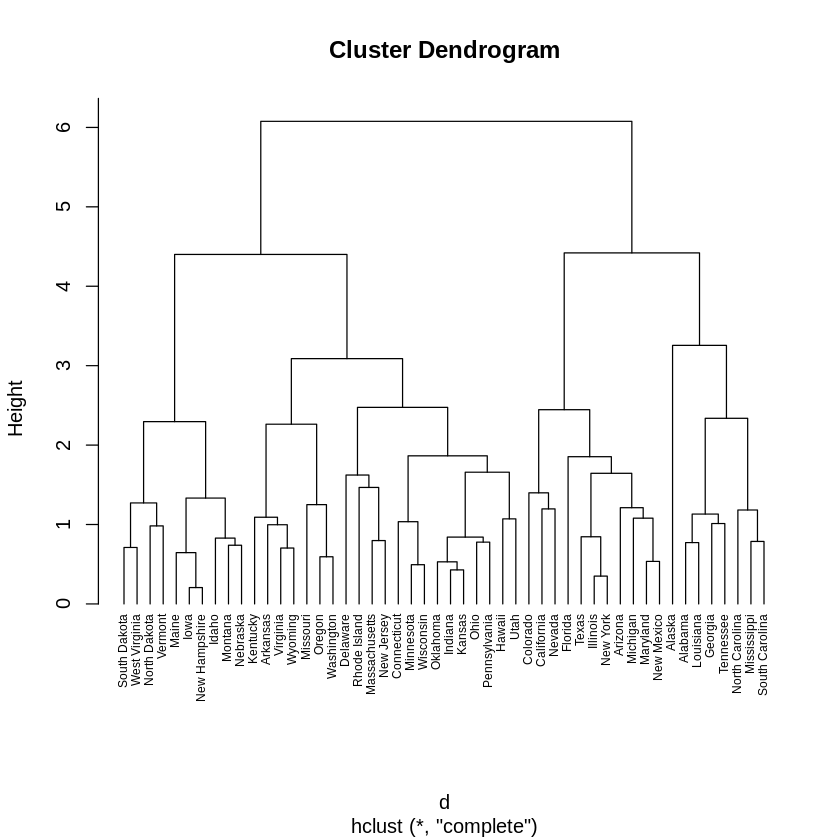

In [ ]:
plot(hc1, cex = 0.6, hang = -1)

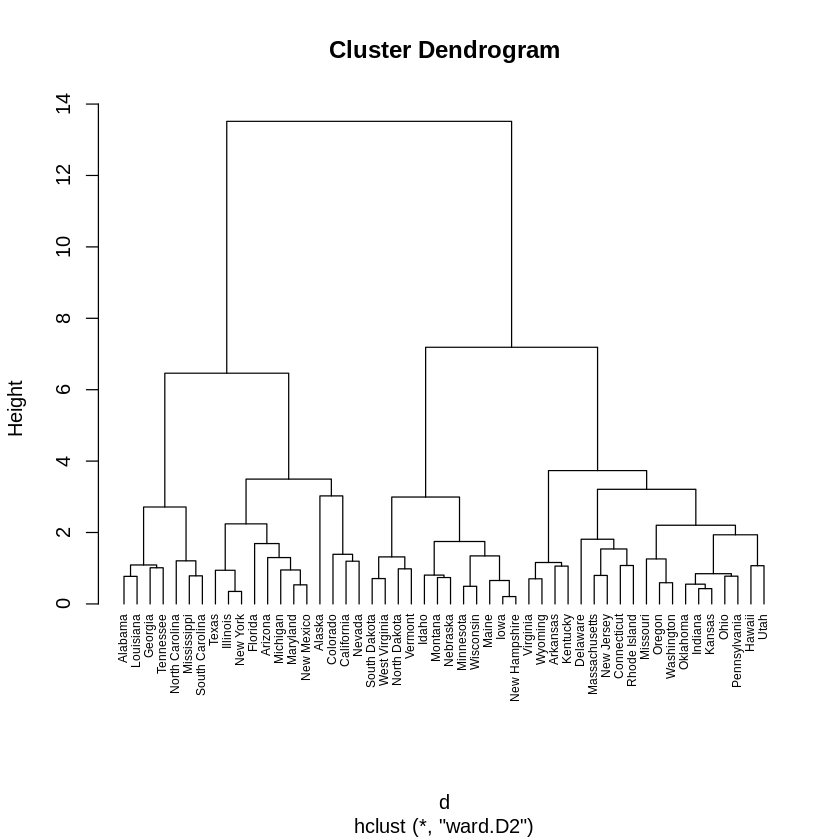

In [ ]:
plot(hc2, cex = 0.6, hang = -1)

K medias es muy útil para datos continuos
Ward es más estable

Existen algunos métodos para determinar la mejor liga a utilizar.

Cortar el dendograma para obtener clusters

In [ ]:
sub_grp <- cutree(hc1, k = 4) # cortamos en 4 grupos

In [ ]:
table(sub_grp) #miembros por grupo

sub_grp
 1  2  3  4 
 8 11 21 10 

Podemos agregar el cluster a los datos

In [ ]:
USArrests %>% mutate(cluster = sub_grp) %>%  head

,Murder,Assault,UrbanPop,Rape,cluster
,<dbl>,<int>,<int>,<dbl>,<int>
Alabama,13.2,236,58,21.2,1
Alaska,10.0,263,48,44.5,1
Arizona,8.1,294,80,31.0,2
Arkansas,8.8,190,50,19.5,3
California,9.0,276,91,40.6,2
Colorado,7.9,204,78,38.7,2


Podemos graficar el dendograma ilustrando los clusters

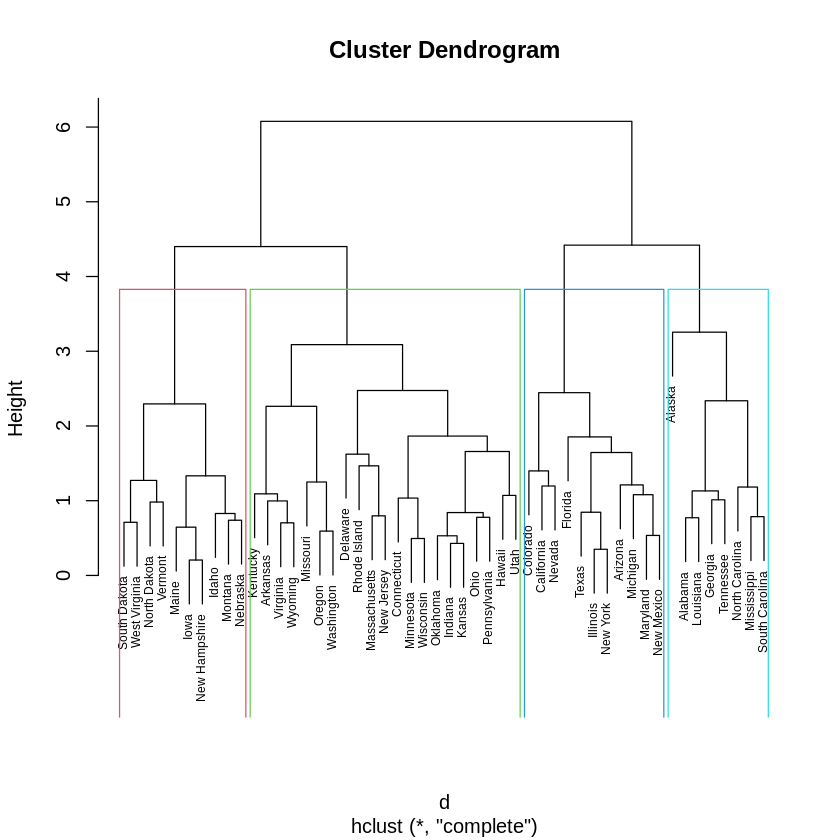

In [ ]:
plot(hc1, cex = 0.6)
rect.hclust(hc1, k = 4, border = 2:5)

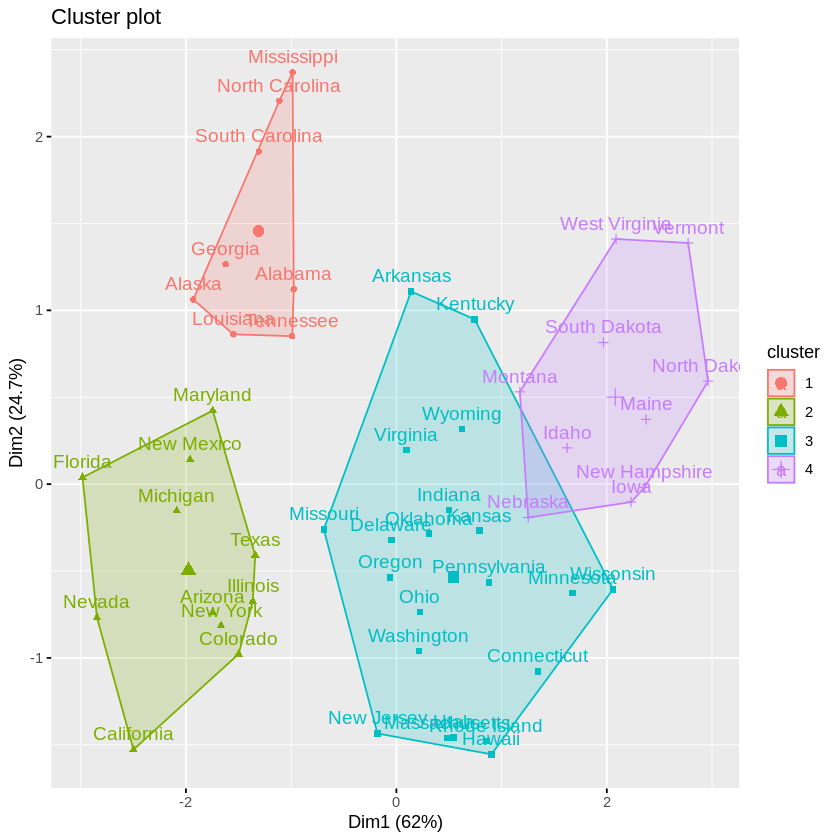

In [ ]:
fviz_cluster(list(data = USArrests, cluster = sub_grp))

In [ ]:
head(USArrests)

,Murder,Assault,UrbanPop,Rape
,<dbl>,<int>,<int>,<dbl>
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6
Colorado,7.9,204,78,38.7
